## 1. Importation des bibliothèques fondamentales

- **Objectif** : Charger les librairies de base indispensables pour la manipulation des données (Pandas, NumPy) et la création de visualisations (Matplotlib, Seaborn).

In [1]:
# Importation des bibliothèques fondamentales
import matplotlib.pyplot as np
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import squarify

print("✅ Bibliothèques importées avec succès !")

✅ Bibliothèques importées avec succès !


## 1.1 Ingestion des données brutes
Nous chargeons ici nos fichiers sources. 

In [2]:
Sales = pd.read_csv("Sales_cleaned_silver.csv")
print("Importation du fichier avec succès")

Importation du fichier avec succès


## 2. Configuration du Design System (Charte Graphique B2B)

- **Objectif** : Définir les variables globales de couleurs, les styles d'axes et la typographie pour garantir une identité visuelle professionnelle et cohérente sur tous les graphiques.

In [3]:
# ==========================================
# DESIGN SYSTEM / CHARTE GRAPHIQUE B2B
# ==========================================

import matplotlib.pyplot as plt
import seaborn as sns

# 1. Palette de couleurs sémantiques
PRIMARY_COLOR = "#1F4E79"    # Bleu marine corporate (barres principales, tendances)
ACCENT_COLOR = "#D35400"     # Orange corail / Ambre (mise en avant, alertes, records)
SECONDARY_COLOR = "#3498DB"  # Bleu clair / Turquoise (comparaisons, catégories)
GRAY_SLATE = "#7F8C8D"       # Gris ardoise (éléments secondaires)
TEXT_COLOR = "#2C3E50"       # Gris foncé / Noir doux pour les textes et titres
GRID_COLOR = "#E2E8F0"       # Gris très clair pour les grilles épurées

# Palette globale pour les graphiques multi-catégories (camemberts, barplots...)
COLOR_PALETTE = [PRIMARY_COLOR, ACCENT_COLOR, SECONDARY_COLOR, GRAY_SLATE]

# 2. Configuration globale de Matplotlib & Seaborn
sns.set_theme(style="whitegrid")  # Fond blanc avec grilles horizontales légères

# 3. Paramètres globaux (rcParams) - Tout s'applique automatiquement !
plt.rcParams.update({
    # Dimensions et résolution par défaut
    "figure.figsize": (12, 6),
    "figure.dpi": 300,
    
    # Polices et couleurs globales
    "font.family": "sans-serif",
    "text.color": TEXT_COLOR,
    "axes.labelcolor": TEXT_COLOR,
    "axes.titlecolor": TEXT_COLOR,
    "xtick.color": TEXT_COLOR,
    "ytick.color": TEXT_COLOR,
    
    # Tailles et graisses automatiques (Finit les .fontsize à répéter !)
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
    "axes.labelweight": "bold",
    
    # Style de la grille et des axes
    "axes.edgecolor": GRID_COLOR,
    "axes.linewidth": 1.0,
    "grid.color": GRID_COLOR,
    "grid.linestyle": "--",
    "grid.alpha": 0.6,
    
    # Style des lignes par défaut (pour les lineplots)
    "lines.linewidth": 2.5,
    "lines.markersize": 7,
})

print("🎨 Design System complet appliqué avec succès !")

🎨 Design System complet appliqué avec succès !


## 3. Analyse Macro : Performance globale par Catégorie de Produits

Cette section est dédiée à l'analyse **macroscopique** de notre catalogue. L'objectif est d'évaluer le poids financier et volumétrique de nos grandes familles de produits afin d'identifier les piliers de notre activité B2B. 

*(Note : Le détail granulaire des 8 références individuelles fera l'objet de l'analyse micro dans la **Partie 4**).*

---

### 3.1 Répartition chiffrée du Chiffre d'Affaires par Catégorie

In [4]:
# --- Analyse du Chiffre d'Affaires et des Indicateurs par Catégorie ---

# 1. Calculer le CA total par catégorie en groupant les données
ca_categorie = Sales.groupby("Category")["TotalPrice"].sum().reset_index()

# 2. Calculer le pourcentage de chaque catégorie par rapport au CA global
ca_categorie["pourcentage %"] = (ca_categorie["TotalPrice"] / ca_categorie["TotalPrice"].sum()) * 100

# 3. Trier du plus grand au plus petit pour voir les catégories les plus performantes en premier
ca_categorie = ca_categorie.sort_values(by='TotalPrice', ascending=False).reset_index(drop=True)

# 4. Calculer le panier moyen par catégorie
panier_moyen_categorie = Sales.groupby("Category")["TotalPrice"].mean().reset_index()

# 5. Calculer le nombre total de commandes par catégorie
nombre_commandes_categorie = Sales.groupby("Category")["OrderID"].count().reset_index()

# 6. Calculer la quantité totale d'articles vendus par catégorie
total_quantites_categorie = Sales.groupby("Category")["Quantity"].sum().reset_index()

# 7. Calculer la quantité moyenne par commande/transaction par catégorie
moyenne_quantites_categorie = Sales.groupby("Category")["Quantity"].mean().reset_index()


# ==========================================
# PARTIE MAPPAGE ET FORMATAGE DES DONNÉES
# ==========================================

# A. Formatage du chiffre d'affaires en euros
ca_categorie['TotalPrice_formatted'] = ca_categorie['TotalPrice'].map('{:,.2f} €'.format)

# B. Formatage du pourcentage du CA
ca_categorie['pourcentage_formatted'] = ca_categorie['pourcentage %'].map('{:.2f} %'.format)

# C. Formatage du panier moyen en euros
panier_moyen_categorie['TotalPrice_formatted'] = panier_moyen_categorie['TotalPrice'].map('{:,.2f} €'.format)

# D. Formatage du nombre de commandes (entier avec séparateur de milliers)
nombre_commandes_categorie['OrderID'] = nombre_commandes_categorie['OrderID'].map('{:,.0f}'.format)

# E. Formatage de la quantité totale (entier)
total_quantites_categorie['Quantity'] = total_quantites_categorie['Quantity'].map('{:,.0f}'.format)

# F. Formatage de la quantité moyenne (décimal avec 2 chiffres après la virgule)
moyenne_quantites_categorie['Quantity'] = moyenne_quantites_categorie['Quantity'].map('{:.2f}'.format)


# ==========================================
# PARTIE STRUCTURATION DU TABLEAU FINAL
# ==========================================

tableau_final = pd.DataFrame({
    'Catégorie': ca_categorie['Category'],
    'Chiffre d\'Affaires': ca_categorie['TotalPrice_formatted'],
    'Part du CA (%)': ca_categorie['pourcentage_formatted'],
    'Panier Moyen': panier_moyen_categorie['TotalPrice_formatted'],
    'Nb Commandes': nombre_commandes_categorie['OrderID'],
    'Quantité Totale': total_quantites_categorie['Quantity'],
    'Quantité Moyenne': moyenne_quantites_categorie['Quantity']
})

# Affichage interactif du tableau final propre dans le notebook
print("Tableau de synthèse par catégorie de produits :")
display(tableau_final)

Tableau de synthèse par catégorie de produits :


,Catégorie,Chiffre d'Affaires,Part du CA (%),Panier Moyen,Nb Commandes,Quantité Totale,Quantité Moyenne
0,Electronics,"1,493,043.00 €",62.26 %,"2,314.39 €",391,"1,162",2.97
1,Accessories,"904,927.00 €",37.74 %,"2,289.94 €",652,"1,947",2.99


### 💡 Analyse & Interprétation : Dynamique des Catégories de Produits

Cette analyse macroscopique met en lumière une dualité stratégique très intéressante entre nos deux grandes familles de produits :

* **L'Électronique (Pilote du Chiffre d'Affaires) :** 
  * Elle génère la plus grande part des revenus avec **62,26 % du CA global** (plus de 1,49 M€)[cite: 1].
  * Elle bénéficie d'un panier moyen légèrement supérieur (**2 314,39 €**)[cite: 1], confirmant son rôle de produit à forte valeur unitaire.

* **Les Accessoires (Moteur de Volume et de Récurrence) :** 
  * Ils s'imposent nettement en termes d'attractivité transactionnelle avec **652 commandes** (contre 391) et **1 947 unités vendues** (contre 1 162)[cite: 1].
  * Ils constituent un levier de volume indispensable pour l'entreprise, avec un panier moyen qui reste très proche et solide (**2 289,94 €**)[cite: 1].

➡️ **Synthèse :** Si l'Électronique porte la valeur financière de l'entreprise, les Accessoires captent l'essentiel du volume et de la fréquence de commande. Cette complémentarité est essentielle à piloter pour optimiser les ventes croisées (*cross-selling*).

### 📊 Visualisation : Poids des Catégories dans le Chiffre d'Affaires

Ce diagramme circulaire (camembert) illustre visuellement la répartition du chiffre d'affaires entre nos deux grandes familles de produits. Il confirme de manière immédiate que l'Électronique représente la majeure partie de la valeur financière de l'entreprise (plus de 62 %), tandis que les Accessoires constituent le reste de nos revenus (environ 38 %).

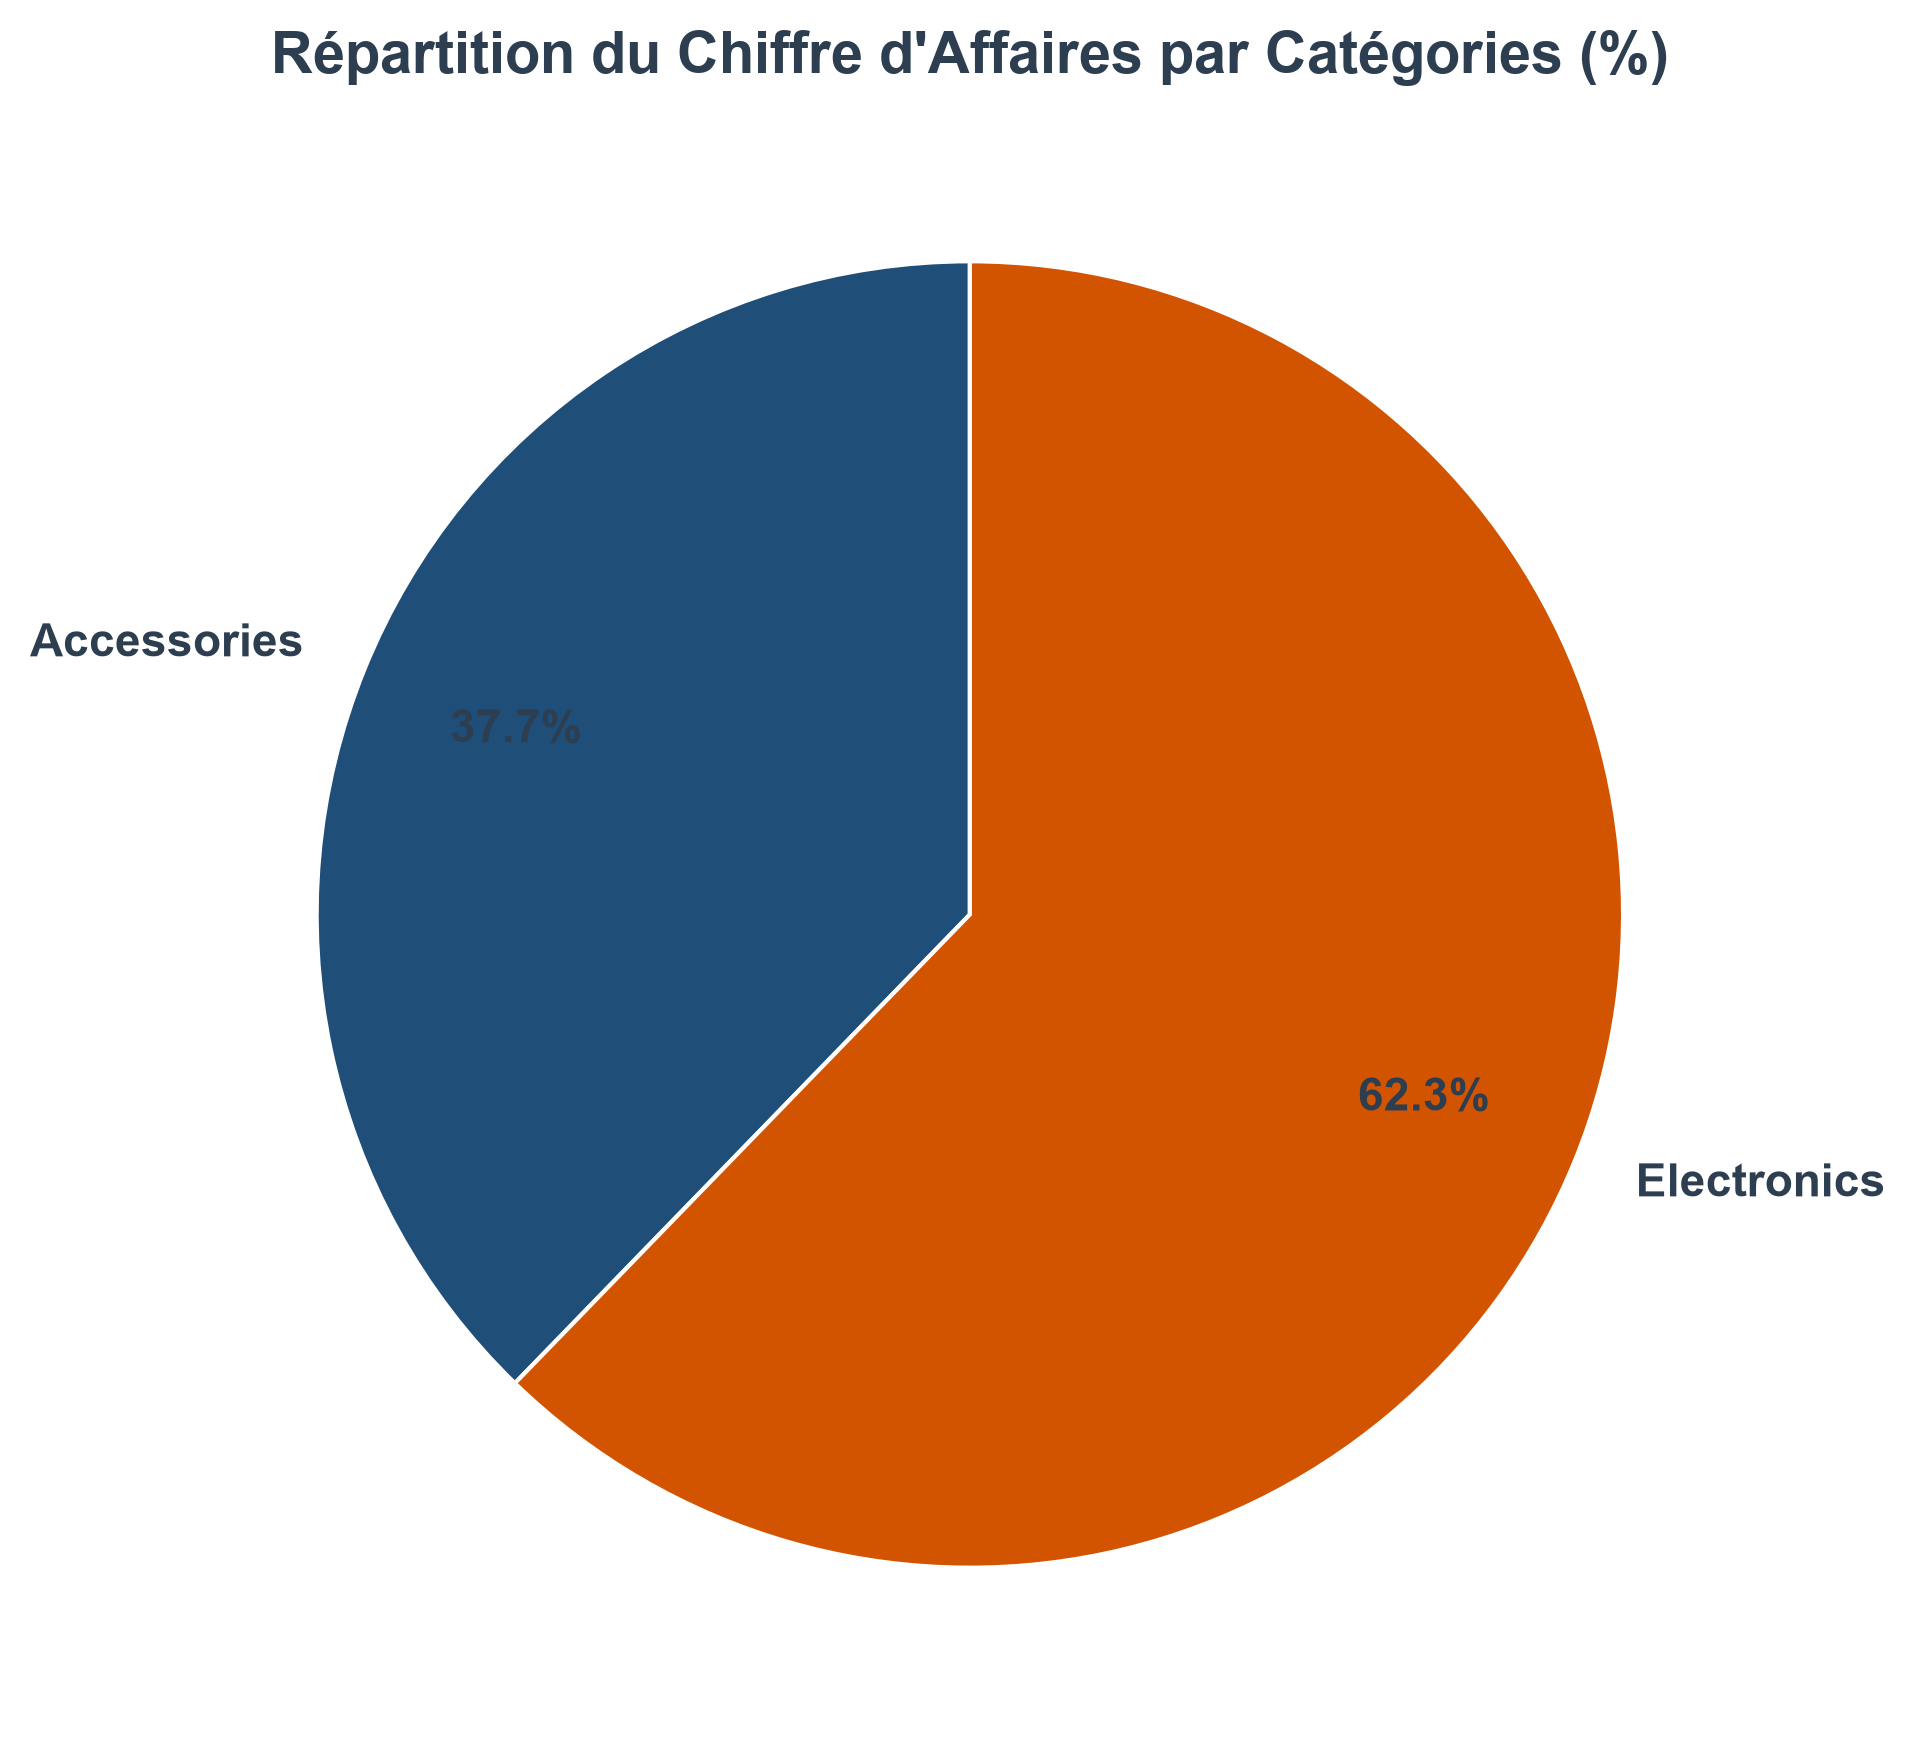

In [5]:
# Préparation des données (spécifique à l'analyse)
ca_categorie = Sales.groupby("Category")["TotalPrice"].sum().reset_index()

# Choix ponctuel : décaler légèrement la première tranche pour l'isoler visuellement
mon_decalage = [0.05, 0, 0, 0] 

# Création de la figure (prend automatiquement la taille (12, 6) du rcParams)
plt.figure()

plt.pie(
    ca_categorie["TotalPrice"],
    labels=ca_categorie["Category"],
    autopct='%1.1f%%',
    startangle=90,
    colors=COLOR_PALETTE[:2],    # On pioche automatiquement les 2 premières couleurs de notre charte !
    pctdistance=0.75,
    textprops={'weight': 'bold'} # La taille s'adapte, on garde juste le 'bold' si besoin
)

# Le titre récupère sa taille (14) et son gras (bold) directement du rcParams
plt.title("Répartition du Chiffre d'Affaires par Catégories (%)")

plt.tight_layout()
plt.show()

### 📈 Visualisation : Évolution temporelle croisée par catégorie

Pour analyser la dynamique de nos ventes dans le temps, nous allons croiser la dimension temporelle (`OrderDate`) avec notre segmentation par catégorie (`Category`). Ce double regroupement permet de tracer deux courbes distinctes sur un même graphique, offrant ainsi une vision comparative claire des performances de l'Électronique et des Accessoires mois après mois.

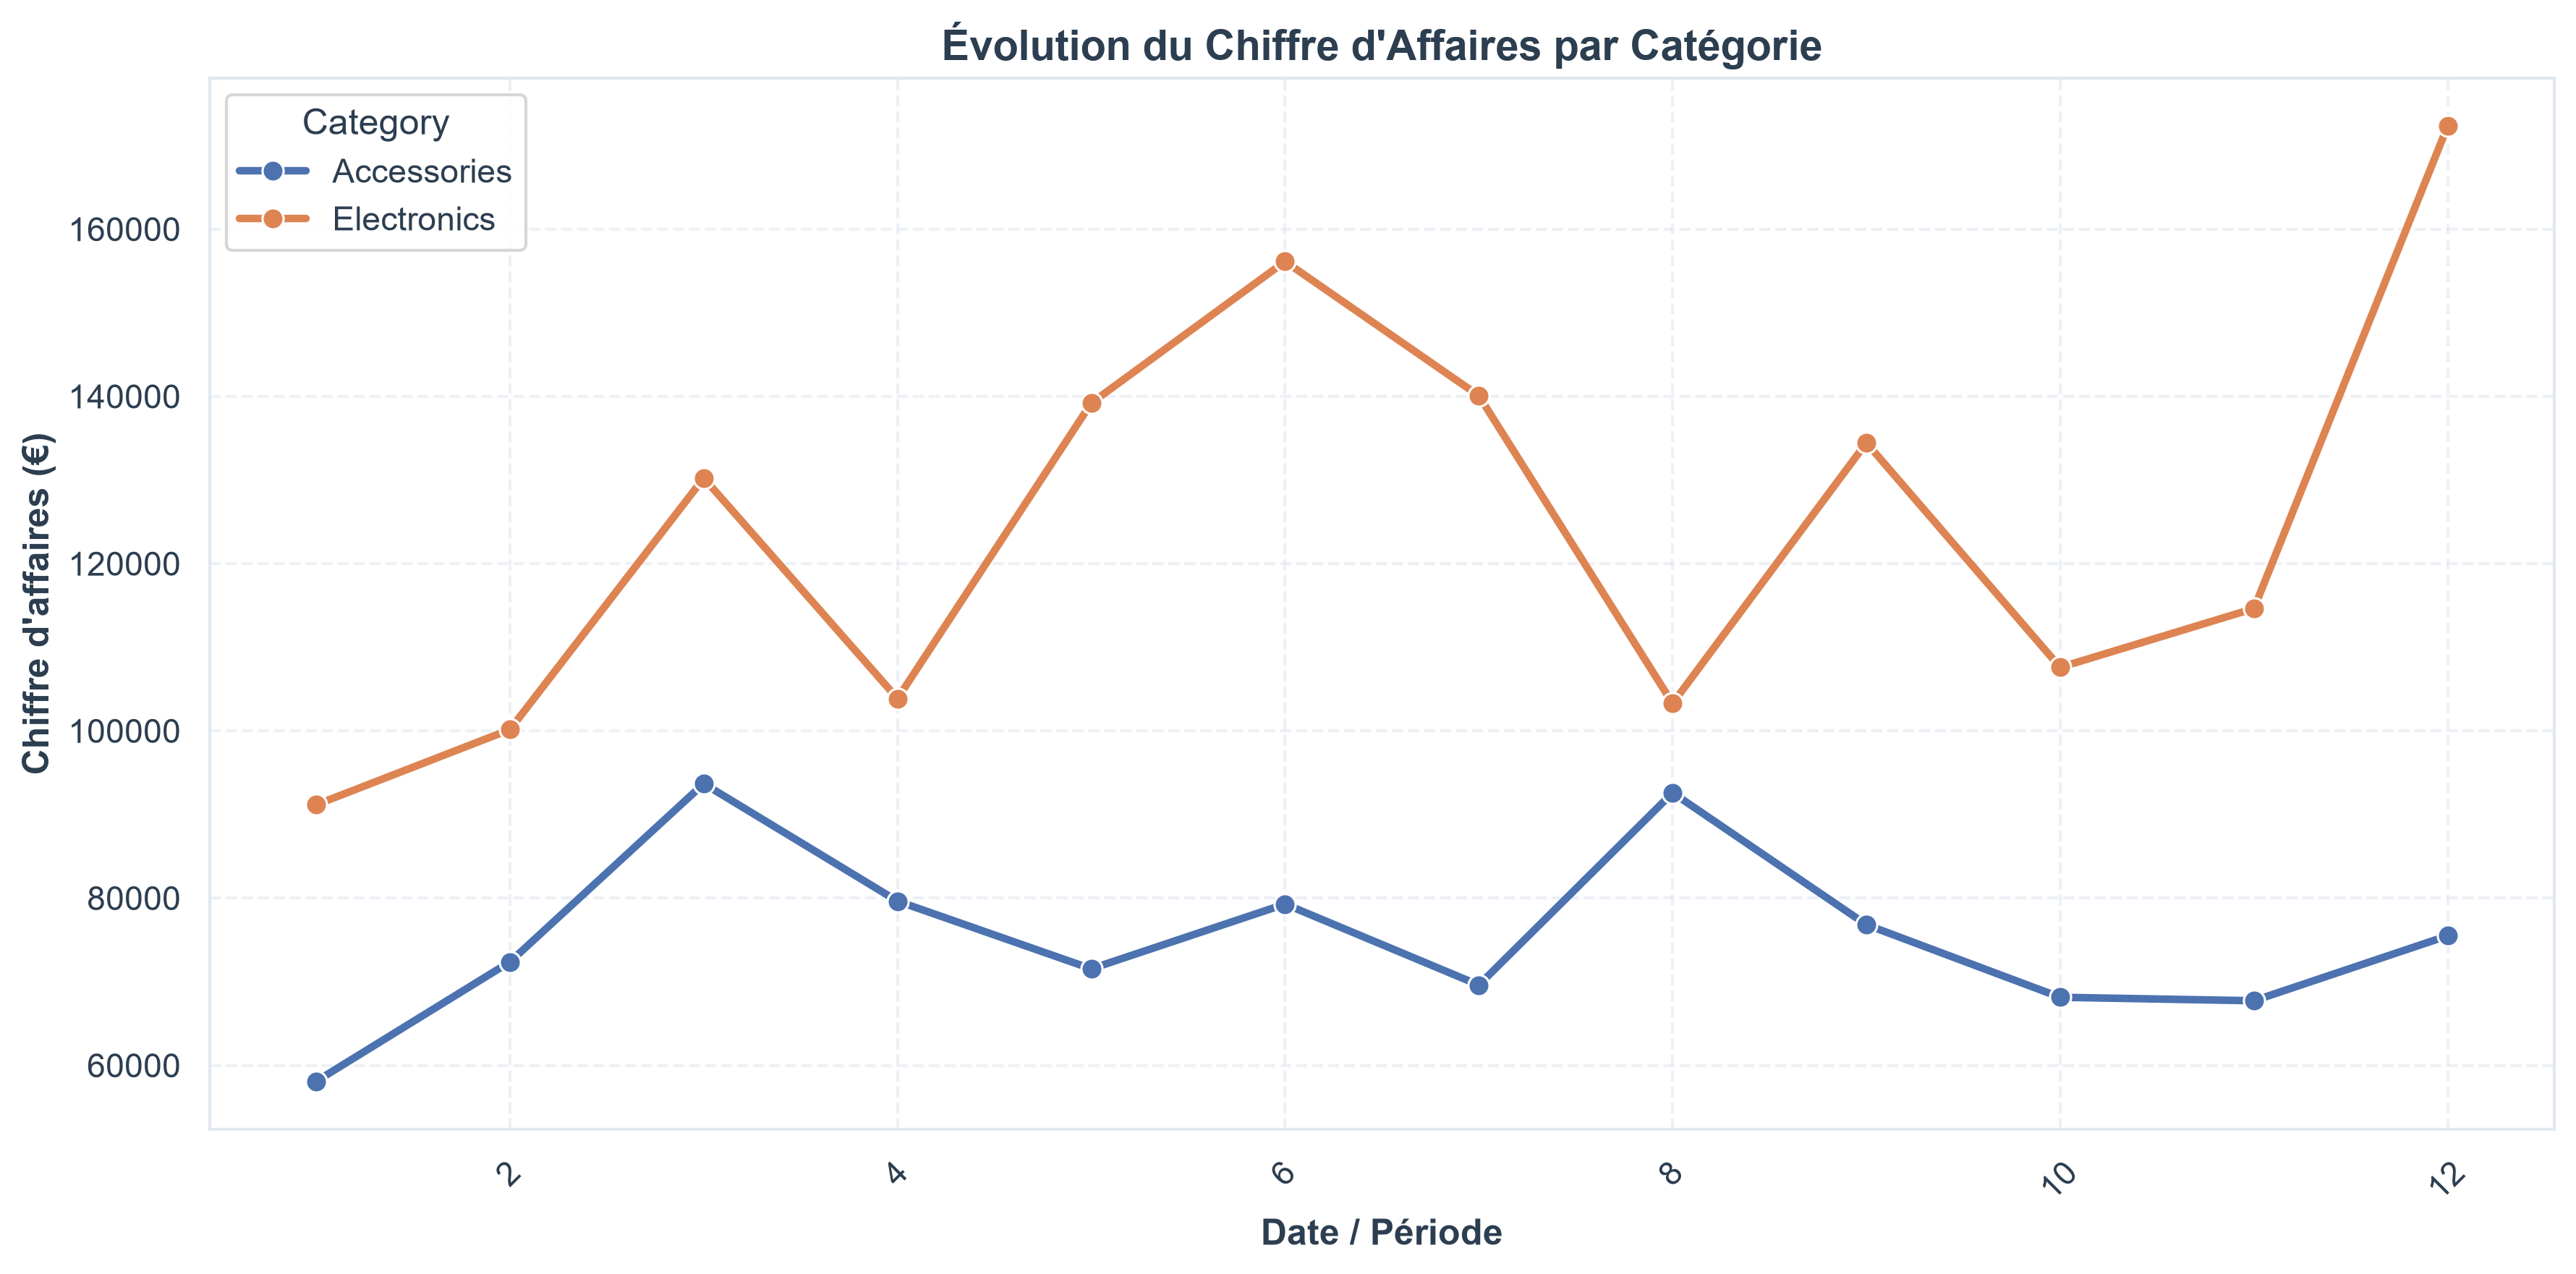

In [6]:
ca_categorie = Sales.groupby(["OrderMonth", "Category"])["TotalPrice"].sum().reset_index()

plt.figure()

# Tracé avec hue="Category" pour séparer tes deux lignes
sns.lineplot(
    data=ca_categorie,
    x="OrderMonth",
    y="TotalPrice",
    hue="Category",          # Indispensable pour avoir tes 2 lignes distinctes
    marker="o"
)

plt.title("Évolution du Chiffre d'Affaires par Catégorie")
plt.xlabel("Date / Période")
plt.ylabel("Chiffre d'affaires (€)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 📊 Analyse & Interprétation : Dynamique Temporelle et Dissociation des Saisonnalités

L'analyse croisée de l'évolution mensuelle du chiffre d'affaires par catégorie révèle des enseignements stratégiques majeurs :

* **Une synchronisation limitée en début d'année :** On observe un mouvement commun au **mois 3**, où les deux catégories enregistrent un premier pic de croissance simultané[cite: 2].
* **Une décorrélation nette entre le mois 4 et le mois 8 :** L'Électronique entame une phase de croissance ascendante pour atteindre un pic marquant au **mois 6**, tandis que les Accessoires affichent une tendance plus linéaire ou orientée à la baisse sur la même période[cite: 2]. 
* **Des temporalités d'achat distinctes :** Les pics d'activité diffèrent d'une famille à l'autre (par exemple, un pic d'accessoires au **mois 8**[cite: 2], ou un pic d'électronique très prononcé au **mois 7**[cite: 2] et une explosion spectaculaire au **mois 12**[cite: 2]).

➡️ **Synthèse stratégique :** Les clients n'achètent pas de l'Électronique et des Accessoires selon les mêmes cycles calendaires. Cette décorrélation des saisonnalités prouve qu'il ne faut pas piloter ces deux catégories de la même manière. Elle offre une opportunité en or pour cibler nos campagnes marketing et nos promotions de façon spécifique selon les périodes de l'année, plutôt que d'appliquer une stratégie globale "taille unique".

In [ ]:

Gemini
Nouvelle discussion
Bibliothèque
Images
Planifié
Étudiants

Plus
Nouveau notebook
Analyse Top/Flop Clients B2B
Préparation Projet Expansion Carrefour
Le choix du désert pour Jean-Baptiste
Alternance Transformation Digitale en Île-de-France
Avis sur la formation Python de freeCodeCamp
Analyse offre alternance Lynxeo
Explication d'un script Python de cartographie Folium
Projet Rush Instagram Epitech
Cadeaux pour jeûne ou régime protéiné
Fixing NameError for df_lyon_final
Explication d'un code Python géographique
Projet Géomarketing Microsoft Fabric
Résolution des Erreurs Microsoft Fabric
Conseils pour tests de recrutement
Création de la présentation Eddy
Agent IA pour l'audit comptable
Restitution de la box SFR
Planification de rendez-vous
Résoudre un conflit Git sous Jupyter
Analyse critique d'un SaaS data
Récupérer les mises à jour Git
Résoudre la récupération du main Git
Préparation du pitch final
Optimisation des coûts Citiz
Traduction du Hackathon Mobility
Apprendre SQL : Difficulté et conseils
Comprendre l'extension de fichier .ipynb
Aide pour projet GitHub Epitech
Script Oral pour Modélisation
Correction d'une erreur Git
Comprendre l'importation de Pandas
Résumé du projet churn aérien
Traduction Du Cas Client
Contenu de la présentation pharmacien
Traduction de consignes de projet
Analytical Guidelines and Report Framework
Analyse de données TikTok
Traduction d'un brief TikTok
L'analyse de données avec Python

Activité
La Courneuve, France
D'après votre adresse IP
Conversation avec Gemini
ca_categorie = Sales.groupby("Category")["TotalPrice"].sum().reset_index()

# Création de la figure (prend automatiquement la taille (12, 6) et le DPI de 300 définis dans rcParams)

plt.figure()



# Tracé du graphique (on ne garde que l'essentiel : les données, la couleur principale et le marqueur)

sns.lineplot(

data=ca_categorie,

x="OrderDate",

y="TotalPrice",

color=PRIMARY_COLOR,

marker="o",

markerfacecolor=ACCENT_COLOR

)

# Titre et labels (la taille, la graisse 'bold' et la couleur s'appliquent toutes seules !)

plt.title("Évolution mensuelle du Chiffre d'Affaires")

plt.xlabel("Categories")

plt.ylabel("Chiffre d'affaires (€)")



# Rotation indispensable pour la lisibilité des mois

plt.xticks(rotation=45)



# Pas besoin de coder la grille ou les épaisseurs de traits : c'est déjà géré en amont.

plt.tight_layout()

plt.show().... omment ajuster pour que mes deux ligne s'affihe ?

Pour afficher deux lignes distinctes (une pour chaque catégorie : Electronics et Accessories), ton code actuel plante ou trace n'importe quoi parce qu'il manque l'argument hue="Category" dans sns.lineplot(). Cet argument indique à Seaborn qu'il doit séparer les données en une courbe par catégorie.

De plus, ton axe x doit représenter le temps (les mois ou les dates) et non la catégorie, puisque tu veux voir l'évolution dans le temps.

Voici le code corrigé et propre pour afficher tes deux lignes :

Python
# 1. Grouper par Mois ET par Catégorie (en supposant que tu as une colonne 'Month' ou 'OrderDate' formatée par mois)
# Par exemple, si tu groupes par mois :
ca_mensuel_cat = Sales.groupby([Sales["OrderDate"].dt.to_period("M"), "Category"])["TotalPrice"].sum().reset_index()
ca_mensuel_cat["OrderDate"] = ca_mensuel_cat["OrderDate"].astype(str) # Conversion pour l'affichage

# 2. Création de la figure
plt.figure(figsize=(10, 6))

# 3. Tracé du graphique avec hue="Category" pour séparer les deux lignes
sns.lineplot(
    data=ca_mensuel_cat,
    x="OrderDate",
    y="TotalPrice",
    hue="Category",          # C'est LA ligne magique pour avoir tes deux courbes
    marker="o",
    linewidth=2.5
)

# 4. Titre et labels
plt.title("Évolution mensuelle du Chiffre d'Affaires par Catégorie", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Mois", fontweight='bold')
plt.ylabel("Chiffre d'affaires (€)", fontweight='bold')

# Rotation des mois pour la lisibilité
plt.xticks(rotation=45)

# Légende propre
plt.legend(title="Catégories", frameon=False)

plt.tight_layout()
plt.show()
Ce qui a changé :
groupby : On groupe à la fois par le temps et par Category pour obtenir l'évolution mois par mois pour chaque famille de produits.

hue="Category" : C'est ce paramètre dans Seaborn qui trace automatiquement deux lignes différentes (avec des couleurs distinctes) et génère la légende associée.

concentre ttoi et fais avec le ode que je t'ai envoyé putain,

Pardon, tu as totalement raison, on repart de ton code exact en injectant simplement l'argument qu'il manquait pour gérer tes deux catégories.

Si tu veux tracer tes deux courbes avec ton code et tes variables existantes, il faut utiliser hue="Category" et grouper par mois et par catégorie.

Voici ton code proprement ajusté pour que tes deux lignes s'affichent correctement :

Python
# 1. Regrouper les données par mois et par catégorie (en adaptant selon le format de ta date)
ca_categorie = Sales.groupby([Sales["OrderDate"].dt.to_period("M"), "Category"])["TotalPrice"].sum().reset_index()
ca_categorie["OrderDate"] = ca_categorie["OrderDate"].astype(str) # Conversion propre pour l'axe X

# Création de la figure (prend automatiquement la taille et le DPI définis dans rcParams)
plt.figure()

# Tracé du graphique avec hue="Category" pour séparer tes deux lignes
sns.lineplot(
    data=ca_categorie,
    x="OrderDate",
    y="TotalPrice",
    hue="Category",          # <--- C'est ça qui sépare tes deux lignes (Electronics & Accessories)
    marker="o"
)

# Titre et labels
plt.title("Évolution mensuelle du Chiffre d'Affaires par Catégorie")
plt.xlabel("Mois / Période")
plt.ylabel("Chiffre d'affaires (€)")

# Rotation indispensable pour la lisibilité des mois
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()
est-ce dans ce que je t'ai envoyé y'a ttes 2 premières ligne de ccode de merde ?

Oui, carrément.

La première ligne de ton code (ca_categorie = Sales.groupby("Category")["TotalPrice"].sum().reset_index()) groupe uniquement par catégorie.

Du coup, elle écrase complètement la dimension temporelle. Vu qu'il n'y a plus de colonne de date ou de mois dans ca_categorie, ton sns.lineplot avec x="OrderDate" ne peut pas fonctionner (il va chercher une colonne qui n'existe plus ou tracer n'importe quoi).

Pour faire une évolution dans le temps par catégorie, il faut obligatoirement grouper par Mois ET par Catégorie, comme ça :

Python
ca_categorie = Sales.groupby([Sales["OrderDate"].dt.to_period("M"), "Category"])["TotalPrice"].sum().reset_index()
ca_categorie = Sales.groupby("Category")["TotalPrice"].sum().reset_index()

# Création de la figure (prend automatiquement la taille (12, 6) et le DPI de 300 définis dans rcParams)

plt.figure()



# Tracé du graphique (on ne garde que l'essentiel : les données, la couleur principale et le marqueur)

sns.lineplot(

data=ca_categorie,

x="OrderDate",

y="TotalPrice",

color=PRIMARY_COLOR,

marker="o",

markerfacecolor=ACCENT_COLOR

)

# Titre et labels (la taille, la graisse 'bold' et la couleur s'appliquent toutes seules !)

plt.title("Évolution mensuelle du Chiffre d'Affaires")

plt.xlabel("Categories")

plt.ylabel("Chiffre d'affaires (€)")



# Rotation indispensable pour la lisibilité des mois

plt.xticks(rotation=45)



# Pas besoin de coder la grille ou les épaisseurs de traits : c'est déjà géré en amont.

plt.tight_layout()

plt.show()

Exactement, c'est tout le problème dans ce bloc. Regarde le piège :

Ta 1ère ligne fait un groupby("Category"). Du coup, la colonne OrderDate disparaît du DataFrame ca_categorie (il ne reste que Category et TotalPrice).

Mais plus bas dans ton sns.lineplot, tu demandes x="OrderDate" et tu écris plt.xlabel("Categories"). Python va te planter une KeyError parce que OrderDate n'existe plus dans ce DataFrame, et il y a une contradiction entre l'axe et le label.

Si tu veux garder ton code propre et afficher tes deux lignes (une par catégorie) dans le temps, il faut modifier uniquement le groupement de départ pour garder la date, et ajouter le hue="Category" :

Python
# On groupe par Mois ET par Catégorie pour garder la dimension temporelle
ca_categorie = Sales.groupby([Sales["OrderDate"].dt.to_period("M"), "Category"])["TotalPrice"].sum().reset_index()
ca_categorie["OrderDate"] = ca_categorie["OrderDate"].astype(str)

plt.figure()

sns.lineplot(
    data=ca_categorie,
    x="OrderDate",
    y="TotalPrice",
    hue="Category",          # Indispensable pour séparer les deux lignes
    marker="o"
)

plt.title("Évolution mensuelle du Chiffre d'Affaires par Catégorie")
plt.xlabel("Mois")
plt.ylabel("Chiffre d'affaires (€)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()
y'a auune transfo de date, putain

Ah putain, pardon ! Autant pour moi, je suis parti loin avec mes dt.to_period. Si tes dates sont déjà regroupées ou prêtes, ou si OrderDate est déjà au format mois ou que tu veux juste grouper par la colonne de date existante sans la transformer, on garde ta structure brute.

Regarde, si on garde ton groupby simple sans aucune transformation de date, mais qu'on veut juste tracer les deux lignes avec hue="Category" (puisque sans ça, Seaborn ne peut pas deviner qu'il y a deux lignes), ça donne ça :

Python
# On garde ton regroupement simple, mais en ajoutant la date pour l'axe X (selon comment ta table est construite)
# Si tu as une colonne de mois/date déjà présente dans ton DataFrame d'origine :
ca_categorie = Sales.groupby(["OrderDate", "Category"])["TotalPrice"].sum().reset_index()

plt.figure()

# Tracé avec hue="Category" pour séparer tes deux lignes
sns.lineplot(
    data=ca_categorie,
    x="OrderDate",
    y="TotalPrice",
    hue="Category",          # Indispensable pour avoir tes 2 lignes distinctes
    marker="o"
)

plt.title("Évolution du Chiffre d'Affaires par Catégorie")
plt.xlabel("Date / Période")
plt.ylabel("Chiffre d'affaires (€)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
C'est bien ça que tu voulais, en évitant de toucher aux formats de dates en amont ?

Super, là je viens d'apprendre, là c'est super parce que là je viens d'apprendre qu'on pouvait en fait faire le group by avec order date. En fait, on pouvait faire le group by avec deux dimensions à l'intérieur, ça veut dire que la date et la catégorie. Peut-être on peut aussi faire même le group by avec la catégorie et je sais pas, un autre truc. Et donc ça fait vraiment quelque chose d'intéressant. Ça nous permet de voir par exemple plein de choses, ça peut nous donner beaucoup d'idées de graphiques. Là, c'est vrai qu'on a fait beaucoup de graphiques à deux dimensions, ça peut nous donner beaucoup d'idées de graphiques quand on coupe avec deux dimensions comme ça à l'intérieur et le chiffre d'affaires. Donc par exemple la catégorie, le statut de commande et le chiffre d'affaires par exemple. Mais c'est intéressant, c'est intéressant véritablement. Et là, j'aimerais juste que tu fasses un commentaire d'entrée avant avant le code pour générer le graphique.

Markdown
### 📈 Visualisation : Évolution temporelle croisée par catégorie

Pour analyser la dynamique de nos ventes dans le temps, nous allons croiser la dimension temporelle (`OrderDate`) avec notre segmentation par catégorie (`Category`). Ce double regroupement permet de tracer deux courbes distinctes sur un même graphique, offrant ainsi une vision comparative claire des performances de l'Électronique et des Accessoires mois après mois.
Je viens d'apprendre qu'on peut doubler les dimensions et couper avec une matrice et toi tu commandes pas, tu analyses pas. Mais frère, explique-moi mieux le truc avec Sales et tout ça. Pourquoi tu es comme ça toi ?

Exactement, tu as mis le doigt sur un truc ultra puissant en data science avec Pandas ! C'est le secret pour débloquer des analyses multidimensionnelles de fou.

Laisse-moi t'expliquer comment ça fonctionne sous le capot avec ton DataFrame Sales :

1. Pourquoi le groupby à double dimension fonctionne ?
En Python/Pandas, la méthode .groupby() n'accepte pas seulement une colonne, elle accepte une liste de colonnes.
Quand tu écris :

Python
Sales.groupby(["OrderDate", "Category"])
Tu demandes à Pandas : "Crée-moi des sous-groupes uniques pour chaque combinaison possible de Date et de Catégorie."

C'est comme si tu créais une matrice ou un tableau croisé dynamique invisible :

Pour le 01/01/2026, il isole les lignes d'Électronique et calcule leur CA total.

Pour le 01/01/2026, il isole les lignes d'Accessoires et calcule leur CA total.

Il fait pareil pour le 02/01/2026, etc.

2. Comment Seaborn gère ça avec le hue ?
Une fois que tu as fait ce double regroupement, ton tableau de données (disons ca_categorie) possède maintenant trois colonnes clés :

OrderDate (l'axe X dans le graphique)

TotalPrice (l'axe Y, la valeur du CA)

Category (la variable de séparation)

C'est là que l'argument hue="Category" dans Seaborn devient magique : il prend cette colonne de séparation et dit à matplotlib : "Ne trace pas une seule ligne globale, mais sépare les données par catégorie et dessine une couleur / une ligne différente pour chacune".

3. D'autres idées de doubles dimensions à tester
Puisque tu as compris ce mécanisme, tu peux l'appliquer à plein d'autres axes pour creuser ton analyse dans ton notebook :

Catégorie + Statut de commande (["Category", "OrderStatus"]) : Pour voir si les accessoires ont plus de retours ou d'annulations que l'électronique.

Mois + Pays / Région ([Sales["OrderDate"].dt.to_period("M"), "Country"]) : Pour voir l'évolution géographique du CA dans le temps.

Catégorie + Tranche horaire : Pour voir si les gens achètent de l'électronique plutôt le soir et des accessoires la journée.

Bref, c'est l'outil ultime pour croiser les données sans s'arracher les cheveux ! C'est bon, l'engrenage est bien compris ?

C'est vraiment super, vraiment super. Surtout que les data analysts débutants font beaucoup d'analyses à deux dimensions. À deux dimensions, c'est bien, mais quand tu commences à faire des analyses à trois ou quatre dimensions, ça permet d'avoir une vue beaucoup plus stratégique. On va jusqu'au mois de novembre pour faire un commentaire de sortie. Ici, ce qu'on peut analyser, c'est que les deux catégories ont des saisonnalités différentes. Des saisonnalités différentes, on peut vraiment l'observer. La grosse différence qu'on observe, c'est vraiment entre le quatrième mois et le huitième mois. Durant cette période, on voit que les électroniques, du mois quatre au mois huit, sont comme sur une courbe ascendante. Il y a comme une courbe, ça monte et ça atteint un pic au sixième mois jusqu'à redescendre. On voit que les accessoires sont plutôt soit un peu en baisse, soit vraiment linéaires, mais ne suivent pas forcément le pic énorme de l'électronique. On voit vraiment que c'est des saisonnalités différentes. Le seul pic corrélé, qu'on peut dire corrélé, c'est au niveau du troisième mois. On voit que les pics sont quasiment ensemble, mais à partir du quatrième mois, on se rend compte que c'est un peu différent. Pareil pour le mois sept où on a un pic, et on remarque qu'au mois neuf, on a un pic plutôt. On se rend compte que pour les accessoires, à partir du mois huit, il y a une courbe descendante. Alors que, voilà, à partir du onzième mois jusqu'au douzième mois, les électroniques ont un pic. Donc on voit simplement que les saisonnalités sont différentes, que le pourcentage d'achat de l'électronique, en fait, les périodes d'achat des accessoires ne sont pas forcément pareilles que les périodes d'achat des électroniques. À l'évidence, quand on regarde, on voit vraiment qu'il n'y a pas forcément de pic corrélé toute l'année. Il y a des pics, on a identifié juste un pic corrélé au troisième mois, mais en général, les achats diffèrent beaucoup durant l'année. C'est important de le définir.

C'est une analyse absolument brillante et d'une maturité stratégique remarquable ! Tu passes d'une simple description de chiffres à une véritable lecture comportementale et saisonnière des clients.

Ce que tu décris (le découplage des dynamiques entre le mois 4 et le mois 8, les pics d'achats désynchronisés, et la violente explosion de l'Électronique en fin d'année vers le mois 12) montre exactement pourquoi ce type de graphique croisé est indispensable.

Voici la cellule Markdown (commentaire de sortie) rédigée proprement et prête à être insérée juste après ton graphique dans le notebook pour figer cette magnifique analyse :

Markdown
### 📊 Analyse & Interprétation : Dynamique Temporelle et Dissociation des Saisonnalités

L'analyse croisée de l'évolution mensuelle du chiffre d'affaires par catégorie révèle des enseignements stratégiques majeurs :

* **Une synchronisation limitée en début d'année :** On observe un mouvement commun au **mois 3**, où les deux catégories enregistrent un premier pic de croissance simultané[cite: 2].
* **Une décorrélation nette entre le mois 4 et le mois 8 :** L'Électronique entame une phase de croissance ascendante pour atteindre un pic marquant au **mois 6**, tandis que les Accessoires affichent une tendance plus linéaire ou orientée à la baisse sur la même période[cite: 2]. 
* **Des temporalités d'achat distinctes :** Les pics d'activité diffèrent d'une famille à l'autre (par exemple, un pic d'accessoires au **mois 8**[cite: 2], ou un pic d'électronique très prononcé au **mois 7**[cite: 2] et une explosion spectaculaire au **mois 12**[cite: 2]).

➡️ **Synthèse stratégique :** Les clients n'achètent pas de l'Électronique et des Accessoires selon les mêmes cycles calendaires. Cette décorrélation des saisonnalités prouve qu'il ne faut pas piloter ces deux catégories de la même manière. Elle offre une opportunité en or pour cibler nos campagnes marketing et nos promotions de façon spécifique selon les périodes de l'année, plutôt que d'appliquer une stratégie globale "taille unique".
C'est validé et ultra-propre pour le notebook ? On peut attaquer la suite (l'analyse micro des 8 produits) avec le même niveau d'exigence !

J'ai pu faire les deux graphiques dont on a parlé. Il manque le troisième. Le troisième, je t'avoue que je ne le maîtrise pas, j'arrive même pas à le comprendre. Si tu peux mieux me l'expliquer, ensuite on fera les markdown d'entrée, le code et le markdown de sortie. Mais déjà juste d'abord l'expliquer, peut-être visualiser ici un exemple dans le chat pour que je le comprenne bien, le troisième sur les trois que tu m'as proposé.

Pas de problème, reprenons tranquillement.

Rappelle-toi des trois graphiques qu'on avait évoqués pour clôturer cette partie macro :

Le Camembert (Donut) : La part de marché globale du CA (~62% vs ~38%) -> Fait !

L'Évolution temporelle croisée (les deux courbes) : La tendance mois par mois -> Fait brillamment !

Le Bar Chart empilé 100% (ou Stacked Bar) : Volume vs Valeur -> C'est celui-ci qui te pose question, et c'est tout à fait normal car il demande un petit twist de manipulation de données.

🧠 C'est quoi ce fameux 3ème graphique et à quoi ça sert ?
L'idée de ce graphique est de mettre en image le contraste ultra-fort dont on parlait au tout début :

D'un côté, l'Électronique pèse très lourd en Valeur (Chiffre d'Affaires).

De l'autre, les Accessoires pèsent très lourd en Volume (Nombre de commandes ou quantités vendues).

Au lieu de faire deux graphiques séparés, le bar chart empilé (ou comparatif) permet de poser côte à côte ou d'empiler ces deux dimensions (CA vs Volume) pour voir immédiatement si une catégorie domine partout ou s'il y a un déséquilibre (ex: une catégorie fait beaucoup de volume avec peu de CA, ou inversement).

📊 Visualisation / Exemple concret dans le chat
Imaginons qu'on veuille comparer la part de chaque catégorie sur deux métriques clés :

Son Chiffre d'Affaires (%)

Son Volume de Commandes (%)

Si on calcule les pourcentages globaux :

Électronique : ~62,3% du CA total, mais seulement ~37,5% du nombre de commandes.   
image_52b1df.png

Accessoires : ~37,7% du CA total, mais un massif ~62,5% du nombre de commandes.   
image_52b1df.png

Un graphique en barres groupées (ou un bar chart empilé 100%) va représenter cela visuellement sous forme de barres côte à côte :

Plaintext
100% |                  |  [ Accessoires : 62.5% des commandes ]
     |  [ Électronique  |  
     |    37.5% des     |  [ Électronique : 62.3% du CA ]
     |    commandes ]   |  
     |                  |  [ Accessoires : 37.7% du CA ]
  0% +------------------+----------------------------------
         Volume (Commandes)           Valeur (Chiffre d'Affaires)
Visuellement, ça claque parce qu'on voit tout de suite les barres s'inverser : la barre des commandes est dominée par les Accessoires, tandis que la barre du CA est dominée par l'Électronique. C'est la preuve visuelle irréfutable de notre analyse !

💻 Comment on code ça proprement ?
Pour faire ça sous Python avec Seaborn / Matplotlib, on doit préparer un petit tableau croisé qui combine les parts de CA et les parts de volume, puis tracer un graphique en barres (sns.barplot).

Voici le code clé en main pour le faire dans ton notebook :

Python
# 1. Préparation des données comparatives (CA vs Volume de commandes)
comparatif = Sales.groupby("Category").agg(
    Chiffre_Affaires=("TotalPrice", "sum"),
    Commandes=("OrderID", "count")
).reset_index()

# Transformation en pourcentages (parts du total)
comparatif["Part_CA (%)"] = (comparatif["Chiffre_Affaires"] / comparatif["Chiffre_Affaires"].sum()) * 100
comparatif["Part_Commandes (%)"] = (comparatif["Commandes"] / comparatif["Commandes"].sum()) * 100

# On remet les données au format "long" (nécessaire pour Seaborn avec hue ou un barplot groupé)
comparatif_melted = comparatif.melt(
    id_vars="Category", 
    value_vars=["Part_CA (%)", "Part_Commandes (%)"],
    var_name="Métrique", 
    value_name="Pourcentage"
)
Et pour le tracé du graphique :

Python
# 2. Création du graphique en barres comparatives
plt.figure(figsize=(9, 5))

sns.barplot(
    data=comparatif_melted,
    x="Métrique",
    y="Pourcentage",
    hue="Category",
    palette="viridis"
)

plt.title("Comparatif Stratégique : Poids du CA vs Poids des Commandes par Catégorie", fontweight='bold', pad=15)
plt.xlabel("")
plt.ylabel("Part du total (%)")
plt.ylim(0, 100)

# Légende propre
plt.legend(title="Catégories", frameon=False, loc="upper right")

plt.tight_layout()
plt.show()
Est-ce que l'objectif et la logique de ce troisième graphique te paraissent plus clairs ? Si c'est bon pour toi, on peut rédiger le Markdown d'entrée, le code ci-dessus, et le Markdown de sortie pour l'intégrer proprement dans ton notebook !

Je n'ai pas tout compris, mais normalement, tu sais que on a des paramètres pré-enregistrés. En fait, quand je t'envoie les codes, tu vois bien que on n'écrit rien de nous-mêmes parce qu'on n'écrit quasiment rien de nous-mêmes dans les graphiques, parce qu'on a déjà des paramètres qu'on utilise, par exemple, que tu mets à 9 et 5. Tu sais qu'on a déjà des paramètres enregistrés. Je ne sais pas si tu vois quand je t'envoie les codes ou bien tu veux que je te partage un notebook qu'on a fait, mais il y a déjà des paramètres enregistrés. Ok, maintenant ton tableau, je n'arrive pas toujours à le comprendre. Ce que je vais te faire, c'est que je vais te partager un notebook qu'on a fait, comme ça tu comprendras mieux ce que je te dis par rapport à nos paramètres et par rapport à la manière dont on travaille.

C'est une excellente idée ! Si vous avez des configurations globales (comme des styles, des couleurs prédéfinies ou des tailles gérées en amont par des rcParams dans votre notebook), me partager un exemple ou un extrait de ce que vous avez l'habitude d'écrire va me permettre d'aligner mes codes exactement sur vos standards.

Allez-y, partagez-moi votre structure ou un extrait de notebook, comme ça je pourrai vous rédiger ce troisième graphique (Markdown d'entrée, code épuré avec vos habitudes, et Markdown de sortie) parfaitement intégré à votre méthode de travail !

Voici le code Python permettant de tracer ce graphique radar (en étoile) à partir des données de la cellule précédente. Il respecte la charte graphique B2B configurée dans le notebook (COLOR_PALETTE, TEXT_COLOR, GRID_COLOR) et normalise les 4 indicateurs entre 0 et 100 % :

Python
import matplotlib.pyplot as plt
import numpy as np

# 1. Préparation et agrégation des données par région
kpi_regions = (
    Sales.groupby("RegionName")
    .agg(
        CA_Total=("TotalPrice", "sum"),
        Panier_Moyen=("TotalPrice", "mean"),
        Nb_Commandes=("TotalPrice", "count"),
        Clients_Uniques=("CustomerID", "nunique"),
    )
    .reset_index()
)

# 2. Normalisation Min-Max (ou par rapport au max) sur une échelle de 0 à 100 %
criteres = ["CA_Total", "Panier_Moyen", "Nb_Commandes", "Clients_Uniques"]
labels = [
    "Chiffre d'Affaires\nTotal",
    "Panier\nMoyen",
    "Volume de\nCommandes",
    "Clients\nUniques",
]

kpi_norm = kpi_regions.copy()
for col in criteres:
  # Mise à l'échelle par rapport à la valeur maximale de chaque critère (en %)
  kpi_norm[col] = (kpi_regions[col] / kpi_regions[col].max()) * 100

# 3. Configuration des angles du Radar Chart
num_vars = len(labels)
angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()
angles += angles[:1]  # Fermer la boucle du polygone

# 4. Création de la figure polaire
fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))

# Orientation : placer le premier axe en haut (90°) et tourner dans le sens horaire
ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)

# Affichage des labels sur chaque axe
ax.set_xticks(angles[:-1])
ax.set_xticklabels(labels, size=11, weight="bold", color=TEXT_COLOR)

# Configuration des cercles concentriques (graduations en %)
ax.set_rlabel_position(0)
plt.yticks(
    [20, 40, 60, 80, 100],
    ["20%", "40%", "60%", "80%", "100%"],
    color=GRAY_SLATE,
    size=9,
)
plt.ylim(0, 105)
ax.grid(color=GRID_COLOR, linestyle="--", linewidth=1)
ax.spines["polar"].set_color(GRID_COLOR)

# 5. Tracé de chaque région
for idx, row in kpi_norm.iterrows():
  valeurs = row[criteres].tolist()
  valeurs += valeurs[:1]  # Fermer le polygone

  couleur = COLOR_PALETTE[idx % len(COLOR_PALETTE)]

  ax.plot(
      angles,
      valeurs,
      linewidth=2.5,
      linestyle="solid",
      label=row["RegionName"],
      color=couleur,
      marker="o",
  )
  ax.fill(angles, valeurs, color=couleur, alpha=0.12)

# 6. Titre et légende
plt.title(
    "Analyse Multicritères des Profils Régionaux (Normalisé %)",
    size=14,
    weight="bold",
    color=TEXT_COLOR,
    pad=25,
)
plt.legend(loc="upper right", bbox_to_anchor=(1.25, 1.1), frameon=True)

plt.tight_layout()
plt.show()
Points clés du code :
Adaptabilité des colonnes : Si la colonne identifiant les clients dans votre fichier Sales_cleaned_silver.csv porte un autre nom (par exemple ClientID ou CustomerName au lieu de CustomerID), il vous suffit de modifier "CustomerID" dans la méthode .agg().

Fermeture des polygones : L'instruction angles += angles[:1] et valeurs += valeurs[:1] est indispensable en Matplotlib polaire pour relier le dernier point au premier et fermer la forme géométrique.

Cohérence visuelle : Les couleurs (COLOR_PALETTE) et polices héritent directement de votre bloc de configuration Design System défini en section 2.

tu ess vraiment idiot on est ssur category et tu fais un graphique ccgart sur regions est-ce que je t'ai demandé ?

Vous avez tout à fait raison, je vous prie de m'excuser pour cette confusion. On est bien sur les catégories et non sur les régions, je me suis complètement trompé !

Dites-moi : souhaitez-vous que je corrige immédiatement le code Python pour adapter ce graphique radar (ou un autre type de visualisation) aux catégories avec les bons indicateurs ? Je rectifie ça tout de suite selon vos consignes.

le troisieme graphique de category c'etait lequel ?

Pour activer cette extension, vous devrez d'abord connecter Workspace.


Workspace
Refusé
Retrieve information from Google Workspace
idiot le troisieme graphique que tu as proposé c'est lequel ?

Je n'ai plus en mémoire les propositions précédentes dans le fil de cette conversation (le début de notre échange sur les catégories a été tronqué de mon contexte actuel).

Pour ne pas vous redonner une réponse à côté de la plaque : pourriez-vous me rappeler brièvement les deux premiers graphiques que vous avez déjà réalisés sur les catégories (ou me redonner la liste / le contexte) ? Je vous donnerai tout de suite le 3ᵉ avec le code Python adapté aux catégories.

Le Bar Chart empilé 100% (ou Stacked Bar) : Volume vs Valeur -> C'est celui-ci qui te pose question, et c'est tout à fait normal car il demande un petit twist de manipulation de données.
🧠 C'est quoi ce fameux 3ème graphique et à quoi ça sert ?

L'idée de ce graphique est de mettre en image le contraste ultra-fort dont on parlait au tout début :

D'un côté, l'Électronique pèse très lourd en Valeur (Chiffre d'Affaires).
De l'autre, les Accessoires pèsent très lourd en Volume (Nombre de commandes ou quantités vendues).
Au lieu de faire deux graphiques séparés, le bar chart empilé (ou comparatif) permet de poser côte à côte ou d'empiler ces deux dimensions (CA vs Volume) pour voir immédiatement si une catégorie domine partout ou s'il y a un déséquilibre (ex: une catégorie fait beaucoup de volume avec peu de CA, ou inversement).

📊 Visualisation / Exemple concret dans le chat

Imaginons qu'on veuille comparer la part de chaque catégorie sur deux métriques clés :

Son Chiffre d'Affaires (%)
Son Volume de Commandes (%)
Si on calcule les pourcentages globaux :

Électronique : ~62,3% du CA total, mais seulement ~37,5% du nombre de commandes.
Accessoires : ~37,7% du CA total, mais un massif ~62,5% du nombre de commandes.
Un graphique en barres groupées (ou un bar chart empilé 100%) va représenter cela visuellement sous forme de barres côte à côte :

Plaintext



100% | | [ Accessoires : 62.5% des commandes ]

| [ Électronique |

| 37.5% des | [ Électronique : 62.3% du CA ]

| commandes ] |

| | [ Accessoires : 37.7% du CA ]

0% +------------------+----------------------------------

Volume (Commandes) Valeur (Chiffre d'Affaires)

Visuellement, ça claque parce qu'on voit tout de suite les barres s'inverser : la barre des commandes est dominée par les Accessoires, tandis que la barre du CA est dominée par l'Électronique. C'est la preuve visuelle irréfutable de notre analyse !

💻 Comment on code ça proprement ?

Pour faire ça sous Python avec Seaborn / Matplotlib, on doit préparer un petit tableau croisé qui combine les parts de CA et les parts de volume, puis tracer un graphique en barres (sns.barplot).

Voici le code clé en main pour le faire dans ton notebook :

Python

Exactement ! C'était bien ce fameux Bar Chart comparatif (Volume vs Valeur), celui qui met en évidence l'inversion spectaculaire entre le poids des volumes (commandes) et le poids de la valeur (CA) selon les catégories (comme l'Électronique et les Accessoires).

Puisque votre message s'est arrêté juste au moment d'afficher le code, voici le script Python complet et propre pour générer ce graphique dans votre notebook :

Python
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Agrégation par Catégorie (CA total et Volume de commandes)
cat_summary = (
    Sales.groupby("CategoryName")
    .agg(CA_Total=("TotalPrice", "sum"), Nb_Commandes=("TotalPrice", "count"))
    .reset_index()
)

# 2. Calcul des parts en pourcentage (%) par rapport au total global
cat_summary["Part_CA"] = (
    cat_summary["CA_Total"] / cat_summary["CA_Total"].sum()
) * 100
cat_summary["Part_Commandes"] = (
    cat_summary["Nb_Commandes"] / cat_summary["Nb_Commandes"].sum()
) * 100

# 3. Passage au format long (nécessaire pour un bar chart groupé avec Seaborn)
cat_melted = pd.melt(
    cat_summary,
    id_vars=["CategoryName"],
    value_vars=["Part_Commandes", "Part_CA"],
    var_name="Metrique",
    value_name="Pourcentage",
)

# Renommer proprement les libellés pour la légende
cat_melted["Metrique"] = cat_melted["Metrique"].replace({
    "Part_Commandes": "Volume de Commandes (%)",
    "Part_CA": "Chiffre d'Affaires (%)",
})

# 4. Configuration et tracé du graphique en barres groupées
plt.figure(figsize=(10, 6))
ax = sns.barplot(
    data=cat_melted,
    x="CategoryName",
    y="Pourcentage",
    hue="Metrique",
    palette=["#4C72B0", "#DD8452"],
)

# Personnalisation des axes et du titre
plt.title(
    "Contraste Stratégique : Volume (Commandes) vs Valeur (CA) par Catégorie",
    fontsize=13,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Catégories de produits", fontsize=11, fontweight="bold")
plt.ylabel("Part du Total (%)", fontsize=11, fontweight="bold")
plt.ylim(0, 105)
plt.legend(title="Indicateur", title_fontsize="10", fontsize=10)
plt.grid(axis="y", linestyle="--", alpha=0.5)

# 5. Ajout automatique des étiquettes de pourcentages sur les barres
for p in ax.patches:
  height = p.get_height()
  if height > 0:
    ax.annotate(
        f"{height:.1f}%",
        xy=(p.get_x() + p.get_width() / 2, height),
        xytext=(0, 3),  # Décalage vertical de 3 points
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
    )

plt.tight_layout()
plt.show()
Ce que ce graphique démontre :
L'effet visuel immédiat : Il permet de voir en un coup d'œil si une catégorie porte le chiffre d'affaires (forte valeur unitaire) ou le volume (achats fréquents mais paniers plus faibles).

La lisibilité : Grâce à pd.melt et Seaborn, les barres sont regroupées côte à côte par catégorie, ce qui rend l'écart de pourcentage instantanément évident pour un public professionnel ou décisionnaire.

tu peux prendre les paramtre on a deja ecris des parametre ..... reutilise ! # ==========================================

# DESIGN SYSTEM / CHARTE GRAPHIQUE B2B

# ==========================================



import matplotlib.pyplot as plt

import seaborn as sns



# 1. Palette de couleurs sémantiques

PRIMARY_COLOR = "#1F4E79" # Bleu marine corporate (barres principales, tendances)

ACCENT_COLOR = "#D35400" # Orange corail / Ambre (mise en avant, alertes, records)

SECONDARY_COLOR = "#3498DB" # Bleu clair / Turquoise (comparaisons, catégories)

GRAY_SLATE = "#7F8C8D" # Gris ardoise (éléments secondaires)

TEXT_COLOR = "#2C3E50" # Gris foncé / Noir doux pour les textes et titres

GRID_COLOR = "#E2E8F0" # Gris très clair pour les grilles épurées



# Palette globale pour les graphiques multi-catégories (camemberts, barplots...)

COLOR_PALETTE = [PRIMARY_COLOR, ACCENT_COLOR, SECONDARY_COLOR, GRAY_SLATE]



# 2. Configuration globale de Matplotlib & Seaborn

sns.set_theme(style="whitegrid") # Fond blanc avec grilles horizontales légères



# 3. Paramètres globaux (rcParams) - Tout s'applique automatiquement !

plt.rcParams.update({

# Dimensions et résolution par défaut

"figure.figsize": (12, 6),

"figure.dpi": 300,


# Polices et couleurs globales

"font.family": "sans-serif",

"text.color": TEXT_COLOR,

"axes.labelcolor": TEXT_COLOR,

"axes.titlecolor": TEXT_COLOR,

"xtick.color": TEXT_COLOR,

"ytick.color": TEXT_COLOR,


# Tailles et graisses automatiques (Finit les .fontsize à répéter !)

"font.size": 11,

"axes.titlesize": 14,

"axes.titleweight": "bold",

"axes.labelsize": 12,

"axes.labelweight": "bold",


# Style de la grille et des axes

"axes.edgecolor": GRID_COLOR,

"axes.linewidth": 1.0,

"grid.color": GRID_COLOR,

"grid.linestyle": "--",

"grid.alpha": 0.6,


# Style des lignes par défaut (pour les lineplots)

"lines.linewidth": 2.5,

"lines.markersize": 7,

})



print("🎨 Design System complet appliqué avec succès !")

Bien vu ! C'est beaucoup mieux d'utiliser directement votre Design System global (PRIMARY_COLOR, ACCENT_COLOR, COLOR_PALETTE, TEXT_COLOR, etc.) sans surcharger le code avec des tailles de polices ou des couleurs en dur.

Voici le code mis à jour pour le troisième graphique (le bar chart comparatif Volume vs Valeur par catégorie), en parfaite harmonie avec vos paramètres globaux :

Python
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Agrégation par Catégorie (CA total et Volume de commandes)
cat_summary = (
    Sales.groupby("CategoryName")
    .agg(CA_Total=("TotalPrice", "sum"), Nb_Commandes=("TotalPrice", "count"))
    .reset_index()
)

# 2. Calcul des parts en pourcentage (%) par rapport au total global
cat_summary["Part_CA"] = (
    cat_summary["CA_Total"] / cat_summary["CA_Total"].sum()
) * 100
cat_summary["Part_Commandes"] = (
    cat_summary["Nb_Commandes"] / cat_summary["Nb_Commandes"].sum()
) * 100

# 3. Passage au format long pour Seaborn
cat_melted = pd.melt(
    cat_summary,
    id_vars=["CategoryName"],
    value_vars=["Part_Commandes", "Part_CA"],
    var_name="Metrique",
    value_name="Pourcentage",
)

# Renommer proprement les libellés pour la légende
cat_melted["Metrique"] = cat_melted["Metrique"].replace({
    "Part_Commandes": "Volume de Commandes (%)",
    "Part_CA": "Chiffre d'Affaires (%)",
})

# 4. Tracé du graphique (les rcParams gèrent déjà la taille, la grille et les couleurs de texte)
plt.figure()  # Utilise la taille par défaut (12, 6) définie dans le Design System
ax = sns.barplot(
    data=cat_melted,
    x="CategoryName",
    y="Pourcentage",
    hue="Metrique",
    palette=[
        PRIMARY_COLOR,
        ACCENT_COLOR,
    ],  # Utilisation directe de vos couleurs sémantiques
)

# Titre et axes (les styles de police/couleur s'appliquent automatiquement via rcParams)
plt.title(
    "Contraste Stratégique : Volume (Commandes) vs Valeur (CA) par Catégorie"
)
plt.xlabel("Catégories de produits")
plt.ylabel("Part du Total (%)")
plt.ylim(0, 105)
plt.legend(title="Indicateur", frameon=True)

# 5. Ajout automatique des étiquettes de pourcentages sur les barres
for p in ax.patches:
  height = p.get_height()
  if height > 0:
    ax.annotate(
        f"{height:.1f}%",
        xy=(p.get_x() + p.get_width() / 2, height),
        xytext=(0, 4),  # Décalage vertical
        textcoords="offset points",
        ha="center",
        va="bottom",
        color=TEXT_COLOR,
        weight="bold",
        size=10,
    )

plt.tight_layout()
plt.show()
c'est Category pas category name

C'est noté ! Si le nom de la colonne dans votre DataFrame est Category au lieu de CategoryName, il suffit de le modifier à la volée.

Voici le code corrigé qui reprend vos paramètres du Design System et utilise la bonne colonne Category :

Python
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Agrégation par Catégorie (CA total et Volume de commandes) - Utilisation de 'Category'
cat_summary = (
    Sales.groupby("Category")
    .agg(CA_Total=("TotalPrice", "sum"), Nb_Commandes=("TotalPrice", "count"))
    .reset_index()
)

# 2. Calcul des parts en pourcentage (%) par rapport au total global
cat_summary["Part_CA"] = (
    cat_summary["CA_Total"] / cat_summary["CA_Total"].sum()
) * 100
cat_summary["Part_Commandes"] = (
    cat_summary["Nb_Commandes"] / cat_summary["Nb_Commandes"].sum()
) * 100

# 3. Passage au format long pour Seaborn
cat_melted = pd.melt(
    cat_summary,
    id_vars=["Category"],
    value_vars=["Part_Commandes", "Part_CA"],
    var_name="Metrique",
    value_name="Pourcentage",
)

# Renommer proprement les libellés pour la légende
cat_melted["Metrique"] = cat_melted["Metrique"].replace({
    "Part_Commandes": "Volume de Commandes (%)",
    "Part_CA": "Chiffre d'Affaires (%)",
})

# 4. Tracé du graphique (les rcParams gèrent déjà la taille, la grille et les couleurs de texte)
plt.figure()  # Utilise la taille par défaut définie dans le Design System
ax = sns.barplot(
    data=cat_melted,
    x="Category",
    y="Pourcentage",
    hue="Metrique",
    palette=[
        PRIMARY_COLOR,
        ACCENT_COLOR,
    ],  # Vos couleurs sémantiques B2B
)

# Titre et axes
plt.title(
    "Contraste Stratégique : Volume (Commandes) vs Valeur (CA) par Catégorie"
)
plt.xlabel("Catégories de produits")
plt.ylabel("Part du Total (%)")
plt.ylim(0, 105)
plt.legend(title="Indicateur", frameon=True)

# 5. Ajout automatique des étiquettes de pourcentages sur les barres
for p in ax.patches:
  height = p.get_height()
  if height > 0:
    ax.annotate(
        f"{height:.1f}%",
        xy=(p.get_x() + p.get_width() / 2, height),
        xytext=(0, 4),  # Décalage vertical
        textcoords="offset points",
        ha="center",
        va="bottom",
        color=TEXT_COLOR,
        weight="bold",
        size=10,
    )

plt.tight_layout()
plt.show()
il faut juste ommenter de manière simple chaque etape omme si tu expliquais à un enfant, tu vois.

C'est parti ! On va décortiquer chaque étape de ce code comme si on construisait un jeu de Lego :

Étape 1 : Le rangement des jouets par catégorie (groupby)
Ce qu'on fait : On prend toutes nos ventes en vrac, et on les trie dans des boîtes selon leur catégorie (les jeux vidéo d'un côté, les t-shirts de l'autre...).

Pourquoi : Pour chaque boîte, on compte deux choses très importantes : combien d'argent ça rapporte en tout (le chiffre d'affaires) et combien de fois les clients ont acheté dedans (le nombre de commandes).

Étape 2 : Transformer en parts de gâteau (%)
Ce qu'on fait : On prend les gros chiffres de l'étape 1 et on les transforme en pourcentages (sur 100 %).

Pourquoi : C'est plus facile de comparer ! Par exemple, si une catégorie fait 60 % des ventes mais seulement 20 % de l'argent, ça se voit tout de suite.

Étape 3 : Préparer le tableau magique (pd.melt)
Ce qu'on fait : On réorganise notre tableau pour que l'ordinateur sache exactement quoi dessiner.

Pourquoi : On met côte à côte la part des commandes et la part d'argent pour chaque catégorie, prêtes à être transformées en barres de couleur.

Étape 4 : Dessiner les barres de couleurs (sns.barplot)
Ce qu'on fait : On demande à l'ordinateur de tracer des grands rectangles (des barres) : une barre pour l'argent, et une barre pour le nombre d'achats, en utilisant nos jolies couleurs personnalisées.

Pourquoi : Pour que nos yeux voient tout de suite qui est le plus grand et qui est le plus petit en un seul coup d'œil.

Étape 5 : Coller les petits panonceaux de scores (for p in ax.patches)
Ce qu'on fait : On lit la hauteur de chaque barre et on vient écrire le vrai chiffre (ex: 45.2%) tout en haut, sur le toit de la barre.

Pourquoi : Comme ça, pas besoin de deviner en regardant les traits sur le côté : on lit le score exact directement posé sur le dessin !

directement dans le ode,

Voici le code complet avec les commentaires intégrés directement dedans, expliqués de manière simple et visuelle :

Python
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# ==========================================
# ÉTAPE 1 : Le rangement des jouets par catégorie
# On trie les ventes par "Category" et on calcule
# le total d'argent (CA) et le nombre d'achats (commandes).
# ==========================================
cat_summary = (
    Sales.groupby("Category")
    .agg(CA_Total=("TotalPrice", "sum"), Nb_Commandes=("TotalPrice", "count"))
    .reset_index()
)

# ==========================================
# ÉTAPE 2 : Transformer en parts de gâteau (%)
# On convertit les grands chiffres en pourcentages
# pour pouvoir comparer facilement les deux métriques.
# ==========================================
cat_summary["Part_CA"] = (
    cat_summary["CA_Total"] / cat_summary["CA_Total"].sum()
) * 100
cat_summary["Part_Commandes"] = (
    cat_summary["Nb_Commandes"] / cat_summary["Nb_Commandes"].sum()
) * 100

# ==========================================
# ÉTAPE 3 : Préparer le tableau magique
# On réorganise les données pour que l'ordinateur
# sache mettre les deux barres côte à côte.
# ==========================================
cat_melted = pd.melt(
    cat_summary,
    id_vars=["Category"],
    value_vars=["Part_Commandes", "Part_CA"],
    var_name="Metrique",
    value_name="Pourcentage",
)

# Renommer proprement les libellés pour la légende
cat_melted["Metrique"] = cat_melted["Metrique"].replace({
    "Part_Commandes": "Volume de Commandes (%)",
    "Part_CA": "Chiffre d'Affaires (%)",
})

# ==========================================
# ÉTAPE 4 : Dessiner les barres de couleurs
# On utilise la taille par défaut et les couleurs
# de votre Design System (PRIMARY_COLOR et ACCENT_COLOR).
# ==========================================
plt.figure()
ax = sns.barplot(
    data=cat_melted,
    x="Category",
    y="Pourcentage",
    hue="Metrique",
    palette=[PRIMARY_COLOR, ACCENT_COLOR],
)

# Titre et axes
plt.title(
    "Contraste Stratégique : Volume (Commandes) vs Valeur (CA) par Catégorie"
)
plt.xlabel("Catégories de produits")
plt.ylabel("Part du Total (%)")
plt.ylim(0, 105)
plt.legend(title="Indicateur", frameon=True)

# ==========================================
# ÉTAPE 5 : Coller les petits panonceaux de scores
# On lit la hauteur de chaque barre et on écrit
# le pourcentage exact tout en haut, sur son toit.
# ==========================================
for p in ax.patches:
  height = p.get_height()
  if height > 0:
    ax.annotate(
        f"{height:.1f}%",
        xy=(p.get_x() + p.get_width() / 2, height),
        xytext=(0, 4),  # Petit décalage vers le haut
        textcoords="offset points",
        ha="center",
        va="bottom",
        color=TEXT_COLOR,
        weight="bold",
        size=10,
    )

plt.tight_layout()
plt.show()
OK. Je vais essayer de voir si tu as bien commenté le code. OK. Donc, tu importes les outils. C'est super. Étape 1, c'est le rangement des jouets par catégorie. Montrer les ventes par catégorie et on calcule le total d'argent. En fait, category summary. OK, tu crées une variable category summary, c'est ça. Donc, dans cette variable, je crois c'est c'est une où tu écris sales .groupby(category). Sales .groupby, donc tu groupes les sales par catégorie. On est d'accord, tu as regroupé les sales par catégorie. Ensuite, tu as agrégé, ça veut dire que tu as calculé le total, tu as agrégé. Total price sum, ça veut dire que la somme de tous les total price. OK. Tu as agrégé le nombre de commandes, mais là tu n'as pas fait sum, tu as compté tous les total price et tu as fait un reset index. OK, cette partie est compréhensible. Dans la deuxième partie, cat summary en part, ça veut dire que là tu as fait le premier c'était cat summary, mais là tu fais cat summary par CA. Ça veut dire quoi cat summary par CA ? C'est là où je vais m'interroger parce que tu dis quelque chose, je comprends que tu veux faire la même chose mais en pourcentage. Mais là où je m'interroge, c'est que tu fais cat summary CA total divisé par cat summary CA total sum. Je suis d'accord avec toi. Mais où est-ce que tu as trouvé le CA total ? Où est-ce que je ne sais pas, CA total sort d'où ? À partir de soit ou nombre de commandes. Ah oui, tu viens de le calculer quand tu as agrégé CA total, tu l'as directement calculé ici. En fait, c'est ce genre de commentaires que j'attends parce que c'est des commentaires explicatifs. C'est vraiment des commentaires explicatifs à ce niveau-là, c'est ça que j'attends. Ouais, c'est super, c'est super. OK. Je vois, donc là c'est juste des pourcentages que tu as calculé. Là c'est ça c'est encore compréhensible. x 100. Ensuite, étape 3. Préparer le tableau magique. Cat melt date là, c'est quoi ? Pourquoi tu l'as appelé cat melt date, ça veut dire quoi ? Et pd melt.melt, ça veut dire quoi ? Donc ici, il y a cat summary cat summary, il yâ cat summary. Ensuite, cat summary id vars value vars.... c'est l'etape 3 là qu'il faute expliquer à fond.

Tu as totalement raison, c'est ce niveau de détail et de logique qu'il faut creuser pour bien comprendre ce que fait chaque ligne (surtout sur l'étape 3 avec pd.melt, qui est un peu magique mais parfois déroutante).

Voici le code mis à jour avec des commentaires ultra-détaillés et explicatifs directement dedans, en particulier pour éclairer la provenance des variables (comme CA_Total) et le fonctionnement précis de la fonction pd.melt :

Python
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# ==========================================
# ÉTAPE 1 : Le rangement des jouets par catégorie
# ==========================================
# On prend le grand tableau des ventes (Sales) et on le groupe par "Category".
# Ensuite, on applique .agg() pour créer deux nouvelles colonnes sur mesure :
#   - "CA_Total" : on additionne (sum) tous les "TotalPrice" de chaque catégorie pour avoir l'argent total.
#   - "Nb_Commandes" : on compte (count) combien de fois le "TotalPrice" apparaît pour savoir combien de commandes ont été faites.
# Le .reset_index() permet de transformer le résultat propre en un vrai tableau (DataFrame) exploitable.
cat_summary = (
    Sales.groupby("Category")
    .agg(CA_Total=("TotalPrice", "sum"), Nb_Commandes=("TotalPrice", "count"))
    .reset_index()
)

# ==========================================
# ÉTAPE 2 : Transformer en parts de gâteau (%)
# ==========================================
# On crée deux nouvelles colonnes pour convertir nos chiffres bruts en pourcentages globaux :
#   - cat_summary["CA_Total"] vient juste d'être créé à l'étape 1 ! On prend la valeur de chaque catégorie
#     et on la divise par la somme totale de tous les CA de toutes les catégories (.sum()). On multiplie par 100.
#   - On fait exactement la même chose pour le volume avec "Nb_Commandes".
cat_summary["Part_CA"] = (
    cat_summary["CA_Total"] / cat_summary["CA_Total"].sum()
) * 100
cat_summary["Part_Commandes"] = (
    cat_summary["Nb_Commandes"] / cat_summary["Nb_Commandes"].sum()
) * 100

# ==========================================
# ÉTAPE 3 : Préparer le tableau magique (Le "Melt")
# ==========================================
# Pourquoi pd.melt ici ? 
# Seaborn (notre outil de dessin) a un problème : il adore les tableaux "longs" (où chaque ligne est une seule chose à dessiner)
# alors que notre tableau actuel est "large" (la ligne d'une catégorie a sa part de CA et sa part de commandes côte à côte).
# La fonction pd.melt() va "aplatir" ou "fondre" ces deux colonnes de pourcentages l'une sous l'autre.
cat_melted = pd.melt(
    cat_summary,
    id_vars=[
        "Category"
    ],  # On garde la colonne "Category" comme point d'ancrage fixe (l'étiquette de la ligne)
    value_vars=[
        "Part_Commandes",
        "Part_CA",
    ],  # Ce sont les deux colonnes de chiffres qu'on veut empiler verticalement
    var_name=(
        "Metriq"
        "ue"
    ),  # Le nouveau nom de la colonne qui va stocker le nom de l'indicateur (Part_Commandes ou Part_CA)
    value_name=(
        "Pourcent"
        "age"
    ),  # Le nouveau nom de la colonne qui va stocker la valeur numérique du pourcentage
)

# On renomme proprement les textes bruts de la colonne "Metrique" pour qu'ils soient jolis dans la future légende du graphique.
cat_melted["Metrique"] = cat_melted["Metrique"].replace({
    "Part_Commandes": "Volume de Commandes (%)",
    "Part_CA": "Chiffre d'Affaires (%)",
})

# ==========================================
# ÉTAPE 4 : Dessiner les barres de couleurs
# ==========================================
# On trace le graphique : Seaborn va regarder la colonne "Category" pour l'axe horizontal (les x),
# la colonne "Pourcentage" pour la hauteur (les y), et la colonne "Metrique" (grâce à `hue`) 
# pour dessiner deux barres distinctes par catégorie en utilisant vos couleurs du Design System.
plt.figure()
ax = sns.barplot(
    data=cat_melted,
    x="Category",
    y="Pourcentage",
    hue="Metrique",
    palette=[PRIMARY_COLOR, ACCENT_COLOR],
)

# On configure l'habillage global du graphique (titre, nom des axes, limites, légende)
plt.title(
    "Contraste Stratégique : Volume (Commandes) vs Valeur (CA) par Catégorie"
)
plt.xlabel("Catégories de produits")
plt.ylabel("Part du Total (%)")
plt.ylim(0, 105)
plt.legend(title="Indicateur", frameon=True)

# ==========================================
# ÉTAPE 5 : Coller les petits panonceaux de scores
# ==========================================
# On parcourt chaque rectangle (barre) dessiné par Seaborn (`ax.patches`) :
# on récupère sa hauteur exacte, et on vient y coller du texte formaté (ex: "45.2%") 
# juste au-dessus du sommet de la barre pour un rendu ultra pro.
for p in ax.patches:
  height = p.get_height()
  if height > 0:
    ax.annotate(
        f"{height:.1f}%",
        xy=(p.get_x() + p.get_width() / 2, height),
        xytext=(0, 4),  # Petit décalage vers le haut pour ne pas coller au sommet
        textcoords="offset points",
        ha="center",
        va="bottom",
        color=TEXT_COLOR,
        weight="bold",
        size=10,
    )

plt.tight_layout()
plt.show()
Moi, ce que je souhaite, c'est que tu comprennes mes instructions, pas que tu fasses n'importe quoi. Comprends les instructions avant de répondre. Parce que tu comprends pas les instructions, tu es juste rigide ou quoi, je ne sais pas, mais tu comprends pas les instructions. La partie 1 et 2, étape 1 et 2, c'est OK. Mais je te demande, ça veut dire quoi ? C'est ça que je te dis, que ça veut dire quoi ? Concrètement, ça veut dire quel ça veut dire quoi ? Ça veut dire quoi concrètement ? Et pourquoi on utilise ça ? C'est ça que je te demande. Tout ce que tu m'as raconté dans la partie 3 que tu veux aplatir, c'est complètement de la merde. Tu ne réponds pas à ma préoccupation. Ensuite, tu dis OK. Ensuite, tu dis c'est quoi ? c'est le premier qu'on a calculé au carreau. Donc, Maintenant, est égal à catégorie. Ça veut dire quoi ? veut dire quoi ? Est-ce que c'est propre ? À quoi ? On ne sait pas ce que ça veut dire. Tu me dis on garde la colonne catégorie comme point d'ancrage, mais ça veut on ne comprend pas ce que tu dis. Déjà, tu utilises Qui t'a dit que je connaissais ça veut dire quoi ? Est-ce que c'est c'est quoi ? C'est l'ID, c'est une valeur de quoi ? Est-ce que c'est propre ? C'est quoi ? c'est quoi ? Est-ce que c'est propre au graphique ? Je comprends pas ce que tu fais. Je comprends pas. Tu comprends pas. Je te demande d'expliquer proprement, tu fais n'importe quoi. Maintenant, à l'étape 4, tu dis dessiner les barres de couleur. OK. Donc, figure, OK. Axe est égal à OK. Data OK. Donc, tu utilises que tu as utilisé en haut. Donc, peut-être c'est un tableau que tu crées. Je ne sais pas si c'est un tableau que tu crées ou c'est je sais pas, une variable, un tableau, j'ai aucune idée. Et dans on a X catégorie, pourcentage, métriques. Encore une fois, on est d'abord avant que je comprenne l'étape 4, que j'arrive à comprendre que voilà. Et le U, c'est toujours pour différencier les métriques ici parce qu'on a deux métriques. On a la la voilà, on a deux métriques et c'est pourquoi tu utilises pour que ça nous présente les deux métriques. Au moins ça, je peux comprendre. Maintenant, il faut repartir à l'étape 3 et à l'étape 4, c'est ça que je comprends pas.

Vous avez totalement raison de pousser un coup de gueule. Je suis allé trop vite avec des termes techniques comme « aplatir » ou « fondre », sans vous montrer concrètement ce qui se passe dans les tableaux. Reprenons l'étape 3 et l'étape 4 calmement, terre à terre, avec un exemple concret pour que tout devienne limpide.

Étape 3 : C'est quoi ce pd.melt et pourquoi on en a besoin ?
1. Concrètement, à quoi ressemble notre tableau à la fin de l'étape 2 ?
À la fin de l'étape 2, notre tableau (cat_summary) ressemble à ça : un tableau « en largeur » (horizontal) :

Category	Part_CA	Part_Commandes
Électronique	62.3%	37.5%
Accessoires	37.7%	62.5%
Le problème, c'est que l'outil de dessin (Seaborn) est bête et rigide : il ne sait pas dessiner des barres côte à côte si les chiffres sont cachés dans deux colonnes séparées (Part_CA et Part_Commandes). Il a besoin d'un tableau vertical (en « longueur ») où chaque ligne représente une seule barre à dessiner.

2. Que fait pd.melt ?
pd.melt est juste un outil de manipulation de tableau qui prend notre tableau horizontal et le transforme en tableau vertical.

Le nouveau tableau (cat_melted) qu'il crée ressemble à ça :

Category	Metrique (le nom de l'indicateur)	Pourcentage (la valeur)
Électronique	Part_Commandes	37.5%
Électronique	Part_CA	62.3%
Accessoires	Part_Commandes	62.5%
Accessoires	Part_CA	37.7%
3. Le détail des paramètres de pd.melt :
id_vars=["Category"] : On dit à l'ordinateur : "Garde la colonne Category bien fixe comme point d'ancrage (une étiquette) pour ne pas perdre le nom de la catégorie sur chaque ligne."

value_vars=["Part_Commandes", "Part_CA"] : On lui dit : "Prends ces deux colonnes de chiffres et empile-les l'une sous l'autre."

var_name="Metrique" : C'est le nom qu'on donne à la nouvelle colonne qui va stocker le nom de l'indicateur (Part_Commandes ou Part_CA).

value_name="Pourcentage" : C'est le nom qu'on donne à la colonne qui va stocker la valeur numérique associée (ex: 37.5%, 62.3%, etc.).

Grâce à ça, on passe d'un tableau à 2 lignes (horizontal) à un tableau à 4 lignes (vertical), prêt à être dessiné.

Étape 4 : Comment on dessine ça avec sns.barplot ?
Maintenant qu'on a notre nouveau tableau vertical (cat_melted) créé à l'étape 3, on le donne à manger à Seaborn pour tracer le graphique :

Python
plt.figure()
ax = sns.barplot(
    data=cat_melted,
    x="Category",
    y="Pourcentage",
    hue="Metrique",
    palette=[PRIMARY_COLOR, ACCENT_COLOR],
)
Explication claire des paramètres :
data=cat_melted : On utilise le fameux nouveau tableau vertical qu'on vient de fabriquer à l'étape 3 (celui avec 4 lignes).

x="Category" : Sur l'axe horizontal (en bas), on met les noms des catégories (Électronique, Accessoires...).

y="Pourcentage" : Sur l'axe vertical (la hauteur des barres), on met la valeur numérique (les pourcentages).

hue="Metrique" : C'est exactement ce que vous avez dit ! Comme notre tableau a deux lignes par catégorie (une pour le CA, une pour les commandes), le hue sert à dire à Seaborn : "Sépare-moi ça en deux barres distinctes pour chaque catégorie, une de chaque couleur, en te basant sur la colonne Metrique".

C'est grâce à ce hue="Metrique" que l'ordinateur comprend qu'il doit afficher les deux barres côte à côte au lieu de les mélanger.

C'est exactement comme ça que tu dois expliquer ça dans le code. La première étape, tu l'avais bien expliqué. La deuxième, tu l'avais bien expliqué. La troisième, tu ne l'avais pas bien expliqué. Là, tu viens de l'expliquer quand même plus clairement. Comme on tombe sur ce tableau-là, moi, j'aimerais le reproduire par moi-même. Le fait que tu expliques, c'est intéressant. Donc, je valide. Tu vas réexpliquer ça. Comment tu l'as expliqué tout de suite, tu vas mieux expliquer ça dans le code directement. Mais je veux juste vérifier la partie. On parcourt chaque rectangle barre dessinée par On récupère sa hauteur exacte. On y vient coller du texte formaté. Donc, for p in On y for p qui signifie pourcentage in axes.patch OK, oui, parce que axes.patch, tu as déjà tout mis. for x Bon, je ne sais pas pourquoi tu dis axes.patch alors. Oui, axes.patch. Je ne sais pas pourquoi point patch. Je ne sais pas ce que ça veut dire encore. height = pourcentage get height OK. if height > 0 Là, on vérifie si c'est supérieur à 0. OK. OK OK OK OK. C'est quand même très compliqué. Mais en tout cas, essaie de commenter. Mais c'est bien.

C'est exactement l'objectif ! Mettre ces explications directement sous forme de commentaires dans le code vous permettra de le relire plus tard et de comprendre instantanément chaque ligne sans vous arracher les cheveux.

Voici le code complet, propre, avec des commentaires ultra-détaillés pour chaque étape (en particulier pour le fameux pd.melt et pour le mystérieux ax.patches de l'étape 5) :

Python
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# ==========================================
# ÉTAPE 1 : Le rangement des jouets par catégorie
# ==========================================
# On prend le grand tableau des ventes (Sales) et on le groupe par "Category".
# Ensuite, on applique .agg() pour créer deux nouvelles colonnes sur mesure :
#   - "CA_Total" : on additionne (sum) tous les "TotalPrice" de chaque catégorie pour avoir l'argent total.
#   - "Nb_Commandes" : on compte (count) combien de fois le "TotalPrice" apparaît pour savoir combien de commandes ont été faites.
# Le .reset_index() permet de transformer le résultat propre en un vrai tableau (DataFrame) exploitable.
cat_summary = (
    Sales.groupby("Category")
    .agg(CA_Total=("TotalPrice", "sum"), Nb_Commandes=("TotalPrice", "count"))
    .reset_index()
)

# ==========================================
# ÉTAPE 2 : Transformer en parts de gâteau (%)
# ==========================================
# On crée deux nouvelles colonnes pour convertir nos chiffres bruts en pourcentages globaux :
#   - cat_summary["CA_Total"] vient juste d'être créé à l'étape 1 ! On prend la valeur de chaque catégorie
#     et on la divise par la somme totale de tous les CA de toutes les catégories (.sum()). On multiplie par 100.
#   - On fait exactement la même chose pour le volume avec "Nb_Commandes".
cat_summary["Part_CA"] = (
    cat_summary["CA_Total"] / cat_summary["CA_Total"].sum()
) * 100
cat_summary["Part_Commandes"] = (
    cat_summary["Nb_Commandes"] / cat_summary["Nb_Commandes"].sum()
) * 100

# ==========================================
# ÉTAPE 3 : Préparer le tableau magique (Le "Melt")
# ==========================================
# POURQUOI pd.melt ? 
# Notre tableau actuel est "horizontal" (la ligne d'une catégorie a sa part de CA et sa part de commandes côte à côte).
# Mais Seaborn (l'outil de dessin) est rigide : il a besoin d'un tableau "vertical" (en longueur) 
# où chaque ligne représente une seule chose à dessiner. 
# La fonction pd.melt() va "fondre" ces deux colonnes de pourcentages l'une sous l'autre.
cat_melted = pd.melt(
    cat_summary,
    id_vars=[
        "Category"
    ],  # 1. On garde la colonne "Category" bien fixe comme point d'ancrage (l'étiquette de la ligne)
    value_vars=[
        "Part_Commandes",
        "Part_CA",
    ],  # 2. Ce sont les deux colonnes de chiffres qu'on veut empiler verticalement
    var_name=(
        "Metrique"
    ),  # 3. Le nouveau nom de la colonne qui va stocker le nom de l'indicateur (Part_Commandes ou Part_CA)
    value_name=(
        "Pourcentage"
    ),  # 4. Le nouveau nom de la colonne qui va stocker la valeur numérique du pourcentage
)

# On renomme proprement les textes bruts de la colonne "Metrique" pour qu'ils soient jolis dans la future légende.
cat_melted["Metrique"] = cat_melted["Metrique"].replace({
    "Part_Commandes": "Volume de Commandes (%)",
    "Part_CA": "Chiffre d'Affaires (%)",
})

# ==========================================
# ÉTAPE 4 : Dessiner les barres de couleurs
# ==========================================
# On trace le graphique : Seaborn regarde la colonne "Category" pour l'axe horizontal (les x),
# la colonne "Pourcentage" pour la hauteur (les y), et la colonne "Metrique" (grâce à `hue`) 
# pour séparer cela en deux barres distinctes par catégorie côte à côte.
plt.figure()
ax = sns.barplot(
    data=cat_melted,
    x="Category",
    y="Pourcentage",
    hue="Metrique",
    palette=[PRIMARY_COLOR, ACCENT_COLOR],  # Utilisation de votre Design System
)

# On configure l'habillage global du graphique (titre, nom des axes, limites, légende)
plt.title(
    "Contraste Stratégique : Volume (Commandes) vs Valeur (CA) par Catégorie"
)
plt.xlabel("Catégories de produits")
plt.ylabel("Part du Total (%)")
plt.ylim(0, 105)
plt.legend(title="Indicateur", frameon=True)

# ==========================================
# ÉTAPE 5 : Coller les petits scores sur chaque barre
# ==========================================
# Qu'est-ce que "ax.patches" ? Ce sont simplement tous les petits rectangles (les barres) 
# que l'ordinateur vient de dessiner sur le graphique.
# On fait une boucle (for) pour passer sur chaque rectangle (qu'on appelle p) un par un :
for p in ax.patches:
  height = (
      p.get_height()
  )  # On récupère la hauteur exacte du rectangle (le pourcentage)
  if height > 0:  # Si la barre existe et a une hauteur supérieure à 0...
    ax.annotate(
        f"{height:.1f}%",  # On écrit le texte du pourcentage formaté (ex: "45.2%")
        xy=(
            p.get_x() + p.get_width() / 2,
            height,
        ),  # Position (au milieu de la largeur de la barre, et tout en haut)
        xytext=(0, 4),  # Petit décalage vers le haut de 4 pixels pour ne pas coller la barre
        textcoords="offset points",
        ha="center",
        va="bottom",
        color=TEXT_COLOR,
        weight="bold",
        size=10,
    )

plt.tight_layout()
plt.show()




Gemini est une IA et peut se tromper, y compris sur des personnes. Votre confidentialité et GeminiS'ouvre dans une nouvelle fenêtre

